<a href="https://colab.research.google.com/github/degahugo/tp-initiation-llm-student-version/blob/main/mini_projet_sujet_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Projet Sujet B


**Durée estimée** : 3-4 heures. Choisissez **un** des deux sujets. Ils ne demandent que les notions vues dans ce TP.

**Livrables attendus** (pour les deux sujets) :
- code documenté, factorisé (réutilisez `generate`, `generate_structured`...) ;
- une évaluation **quantitative** sur un jeu de test annoté, avec une comparaison de plusieurs approches ;
- une analyse en markdown : ce qui fonctionne, ce qui échoue et pourquoi, pistes d'amélioration.



### Sujet B : classification par les probabilités

Pour classer un texte, on peut laisser le LLM **générer** le label, ou bien **lire directement** dans la distribution du token suivant (partie 2) la probabilité de chaque label. La seconde approche donne un score de confiance, et pas seulement une réponse.

Travaillez sur la polarité de critiques de films en français, avec le dataset [allocine](https://huggingface.co/datasets/tblard/allocine) (`load_dataset("tblard/allocine")`, label 0 = négatif, 1 = positif). Utilisez un échantillon **équilibré** d'environ 200 critiques du split `test`, tronquées si elles sont trop longues.

1. **Approche générative** : avec un system prompt adapté, faire générer `positif` ou `négatif`, analyser la réponse et compter les réponses invalides.
2. **Approche par les probabilités** : appliquer le chat template, faire **un seul** passage dans le modèle et comparer la probabilité du premier token de `positif` et de `négatif`. En déduire un score $P(\text{positif}) / (P(\text{positif}) + P(\text{négatif}))$.
3. Évaluer les deux approches : exactitude, matrice de confusion, temps de calcul ; et pour l'approche par les probabilités, l'aire sous la courbe ROC.
4. Étudier l'effet du **nombre d'exemples** few-shot (0, 2, 4, 8 exemples pris dans le split `validation`) et de leur **ordre** (tous les exemples positifs d'abord, ou tous les négatifs d'abord).
5. Étudier le **calibrage** : quand le modèle est sûr à 90 %, a-t-il raison 90 % du temps ? Tracer l'exactitude en fonction de la confiance (*reliability diagram*).

**Questions** : le modèle a-t-il un biais vers l'un des labels ? Le seuil de 0,5 est-il le bon ? Quels avantages pratiques l'approche par les probabilités présente-t-elle (coût, réponses invalides, possibilité de s'abstenir quand le modèle hésite) ? Quelles critiques sont mal classées, et pourquoi (ironie, critiques nuancées...) ?


## Commande d'installation



In [4]:
%pip install -q -U transformers accelerate datasets evaluate rouge_score

## Imports et GPU

In [13]:
import time
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix, roc_auc_score, roc_curve
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    print("GPU :", torch.cuda.get_device_name(0))
    DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
else:
    print("ATTENTION : pas de GPU, l'exécution sera très lente.")
    DTYPE = torch.float32

set_seed(42)

GPU : Tesla T4


## Modèle

In [6]:
MODEL_NAME = "Qwen/Qwen3-1.7B"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=DTYPE, device_map="auto")
print(f"Mémoire occupée : {model.get_memory_footprint() / 1e9:.1f} Go")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Mémoire occupée : 3.4 Go


## Fonctions du TP importantes  

## Fonction generate

In [7]:
def generate(messages, max_new_tokens=256, enable_thinking=False, **gen_kwargs):
    """Génère la réponse de l'assistant à une liste de messages au format chat."""

    inputs=tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        enable_thinking=enable_thinking,
        return_tensors="pt",
        return_dict=True,
    ).to(model.device)
    output_ids=model.generate(**inputs,max_new_tokens=max_new_tokens,**gen_kwargs)
    #generate renvoie prompt + réponse : on ne décode que les tokens générés
    generated_ids=output_ids[0,inputs["input_ids"].shape[1]:]
    return tokenizer.decode(generated_ids,skip_special_tokens=True).strip()

## données

In [8]:
allocine = load_dataset("tblard/allocine")
print(allocine)

LABELS = {0: "négatif", 1: "positif"}
print(allocine["test"][0])

README.md:   0%|          | 0.00/9.31k [00:00<?, ?B/s]

allocine/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 60.0MB            

allocine/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

allocine/validation-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 7.58MB            

allocine/validation-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

allocine/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 7.58MB            

allocine/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/160000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/20000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['review', 'label'],
        num_rows: 160000
    })
    validation: Dataset({
        features: ['review', 'label'],
        num_rows: 20000
    })
    test: Dataset({
        features: ['review', 'label'],
        num_rows: 20000
    })
})
{'review': 'Magnifique épopée, une belle histoire, touchante avec des acteurs qui interprètent très bien leur rôles (Mel Gibson, Heath Ledger, Jason Isaacs...), le genre de film qui se savoure en famille! :)', 'label': 1}


### Préparation des échantillons

In [22]:
from datasets import concatenate_datasets

N_PER_CLASS=100 #100 critiques positives et 100 critiques négatives
MAX_REVIEW_TOKENS=256 #longueur maximale d'une critique

def truncate(text,max_tokens=MAX_REVIEW_TOKENS):
  "Tronque un texte à max_token"
  ids=tokenizer(text,add_special_tokens=False)["input_ids"]
  if len(ids)<=max_tokens:
    return text
  return tokenizer.decode(ids[:max_tokens])+"[...]"

# 100 critiques de chaque classe, tirées au hasard dans le split test
test=allocine["test"].shuffle(seed=42)
positives=test.filter(lambda ex:ex["label"]==1).select(range(N_PER_CLASS))
negatives=test.filter(lambda ex:ex["label"]==0).select(range(N_PER_CLASS))

#On réunit les deux moitiés puis on mélange
eval_ds=concatenate_datasets([positives,negatives]).shuffle(seed=42)

reviews=[truncate(review) for review in eval_ds["review"]]
y_true=np.array(eval_ds["label"])

print(f"{len(reviews)} critiques, {y_true.mean():.0%} positives")
print(reviews,y_true)


200 critiques, 50% positives
["Film ennuyeux.... une scène de lecture longue et incompréhensible.... film très décousu.... je n' y ai vu aucun intérêt, je ne comprends l'enthousiasme des critiques de la presse.... je me suis même demandée s' ils avaient vu le film.... le seul point intéressant c' est qu' on sent en arrière plan... mais de très quelques caractéristiques de la culture japonaise....", 'En terme d\'animation, il y a de formidables sèquences dans "Hotel Transylvania" qui parviennent à surprendre à chaque instant! En termes de ton et d\'èmotion, les scènaristes n\'ont pas voulu empièter sur tous les moments touchants car parfois c\'est bien de relâcher la tension! il faut trouver l\'èquilibre lors d\'un passage èmouvant, savoir s\'il faut mettre une blague ou la retirer! On jongle avec tout ça dans cet excellent film d\'animation où chaque image est particulièrement travaillèe! Très drôle (Dracula qui danse, c\'est poilant), "Hotel Transylvania", c\'est avant un grand profes

## q1


In [21]:
CLS_SYSTEM_PROMPT = (
    "Tu es un classifieur de sentiment pour des critiques de films. "
    "Réponds uniquement par un seul mot, en minuscules : positif ou négatif."
)

def make_cls_messages(review, shots=(), system_prompt=CLS_SYSTEM_PROMPT):
    """Construit la conversation : system prompt, exemples éventuels (étape 4), puis la critique à classer."""
    messages = [{"role": "system", "content": system_prompt}]
    for shot in shots:  # un tour (user, assistant) par exemple
        messages += [
            {"role": "user", "content": shot["review"]},
            {"role": "assistant", "content": LABELS[shot["label"]]},
        ]
    messages.append({"role": "user", "content": review})
    return messages

def parse_label(text):
    """Transforme la réponse du modèle en label : 1 = positif, 0 = négatif, -1 = réponse invalide."""
    word = re.sub(r"\W", "", text.lower())  # minuscules, sans ponctuation ni ** (les accents sont gardés)
    if word.startswith("positi"):
        return 1
    if word.startswith(("négati", "negati")):
        return 0
    return -1


start = time.perf_counter()
raw_answers = [generate(make_cls_messages(review), max_new_tokens=5, do_sample=False) for review in reviews]
gen_time = time.perf_counter() - start

gen_pred = np.array([parse_label(answer) for answer in raw_answers])

print(f"Temps : {gen_time:.1f} s ({gen_time / len(reviews):.2f} s par critique)")
print(f"Réponses invalides : {(gen_pred == -1).sum()} sur {len(reviews)}")
print(f"Exactitude : {(gen_pred == y_true).mean():.3f}")

# Quelques exemples pour vérifier que parse_label fonctionne
for answer, pred, true in list(zip(raw_answers, gen_pred, y_true))[:10]:
    print(f"réponse brute : {answer!r:15} -> {pred:2} | vrai label : {true}")

# Les réponses invalides, s'il y en a
print("Exemples de réponses invalides :", [a for a, p in zip(raw_answers, gen_pred) if p == -1][:5])

Temps : 34.4 s (0.17 s par critique)
Réponses invalides : 0 sur 200
Exactitude : 0.870
réponse brute : 'négatif'       ->  0 | vrai label : 0
réponse brute : 'positif'       ->  1 | vrai label : 1
réponse brute : 'négatif'       ->  0 | vrai label : 0
réponse brute : 'positif'       ->  1 | vrai label : 1
réponse brute : 'positif'       ->  1 | vrai label : 1
réponse brute : 'positif'       ->  1 | vrai label : 1
réponse brute : 'positif'       ->  1 | vrai label : 1
réponse brute : 'négatif'       ->  0 | vrai label : 0
réponse brute : 'négatif'       ->  0 | vrai label : 0
réponse brute : 'négatif'       ->  0 | vrai label : 1
Exemples de réponses invalides : []


### q2


In [23]:
# Découpage de chaque label en tokens : on ne garde que le premier
pos_tokens = tokenizer("positif", add_special_tokens=False)["input_ids"]
neg_tokens = tokenizer("négatif", add_special_tokens=False)["input_ids"]

print("positif ->", tokenizer.convert_ids_to_tokens(pos_tokens))
print("négatif ->", tokenizer.convert_ids_to_tokens(neg_tokens))

POS_ID, NEG_ID = pos_tokens[0], neg_tokens[0]
assert POS_ID != NEG_ID, "Les deux labels commencent par le même token : choisir d'autres mots."

positif -> ['posit', 'if']
négatif -> ['n', 'Ã©g', 'atif']


In [27]:
def label_score(review,shots=()):
  """Renvoie (score, masse) pour une critique.

  score = P(positif) / (P(positif) + P(négatif))
  masse = P(positif) + P(négatif) : à quel point le modèle veut répondre par l'un des deux labels
  """
  inputs=tokenizer.apply_chat_template(
    make_cls_messages(review,shots),
    add_generation_prompt=True,
    enable_thinking=False,
    return_tensors="pt",
    return_dict=True,
  ).to(model.device)
  with torch.no_grad():
    logits = model(**inputs).logits[0, -1]  # un seul passage, dernière position
  probs=torch.softmax(logits.float(),dim=-1)
  p_pos,p_neg=probs[POS_ID].item(),probs[NEG_ID].item()
  return p_pos/(p_pos+p_neg),p_pos+p_neg

for review, true in zip(reviews[:5], y_true[:5]):
    score, mass = label_score(review)
    print(f"vrai label : {true} | score : {score:.3f} | masse : {mass:.3f}")


vrai label : 0 | score : 0.000 | masse : 0.988
vrai label : 1 | score : 1.000 | masse : 1.000
vrai label : 0 | score : 0.000 | masse : 0.993
vrai label : 1 | score : 1.000 | masse : 1.000
vrai label : 1 | score : 1.000 | masse : 1.000


In [28]:
start = time.perf_counter()
results_proba = [label_score(review) for review in reviews]
proba_time = time.perf_counter() - start

proba_scores = np.array([score for score, _ in results_proba])
proba_masses = np.array([mass for _, mass in results_proba])
proba_pred = (proba_scores > 0.5).astype(int)

print(f"Temps : {proba_time:.1f} s ({proba_time / len(reviews):.2f} s par critique)")
print(f"Exactitude : {(proba_pred == y_true).mean():.3f}")
print(f"Masse moyenne P(positif) + P(négatif) : {proba_masses.mean():.3f}")
print(f"Prédit positif : {proba_pred.mean():.0%} (vrai : 50 %)")

Temps : 13.2 s (0.07 s par critique)
Exactitude : 0.870
Masse moyenne P(positif) + P(négatif) : 0.981
Prédit positif : 39% (vrai : 50 %)


### q3


In [37]:
results=[]

def report(name,y_pred,elapsed,scores=None):
  """Ajoute une ligne au tableau des résultats. Une réponse invalide (-1) compte comme une erreur"""
  results.append({
      "approche":name,
      "exactitude":accuracy_score(y_true,y_pred),
      "invalides":int((y_pred==-1).sum()),
      "prédit positif":(y_pred==1).mean(),
      "temps (s)":elapsed,
      "temps /critiques (s)":elapsed/len(y_pred),
      "AUC":roc_auc_score(y_true,scores) if scores is not None else np.nan,
  })


report("génératif, 0 ex.",gen_pred,gen_time)
report("probas, 0 ex.",proba_pred,proba_time,proba_scores)

pd.DataFrame(results).set_index("approche").round(3)

,exactitude,invalides,prédit positif,temps (s),temps /critiques (s),AUC
approche,,,,,,
"génératif, 0 ex.",0.87,0,0.39,34.375,0.172,NaN
"probas, 0 ex.",0.87,0,0.39,13.179,0.066,0.967


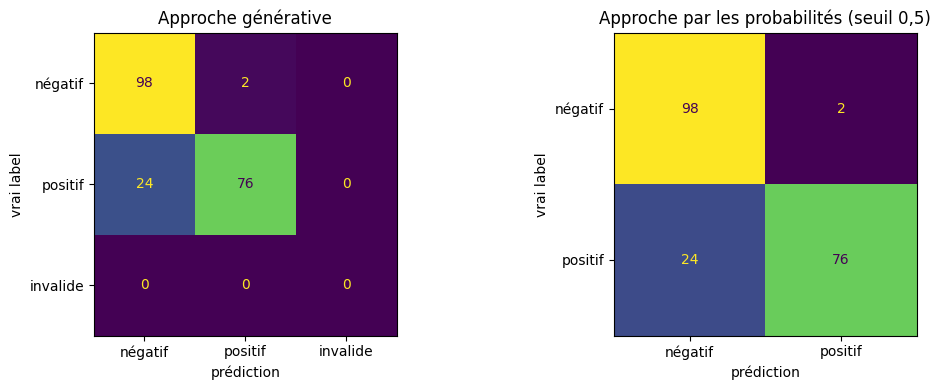

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_true, gen_pred, labels=[0, 1, -1], display_labels=["négatif", "positif", "invalide"],
    ax=axes[0], colorbar=False,
)
axes[0].set_title("Approche générative")

ConfusionMatrixDisplay.from_predictions(
    y_true, proba_pred, labels=[0, 1], display_labels=["négatif", "positif"],
    ax=axes[1], colorbar=False,
)
axes[1].set_title("Approche par les probabilités (seuil 0,5)")

for ax in axes:
    ax.set_xlabel("prédiction")
    ax.set_ylabel("vrai label")
plt.tight_layout()
plt.show()

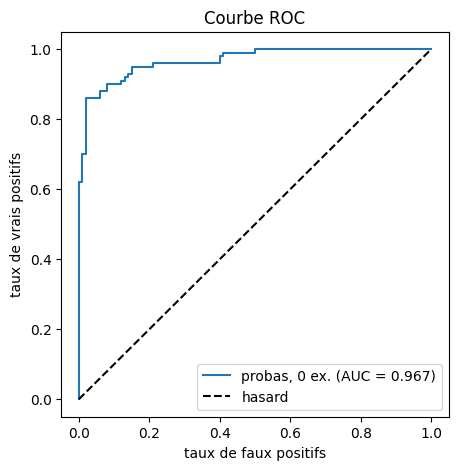

In [39]:
fpr, tpr, _ = roc_curve(y_true, proba_scores)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"probas, 0 ex. (AUC = {roc_auc_score(y_true, proba_scores):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="hasard")
plt.xlabel("taux de faux positifs")
plt.ylabel("taux de vrais positifs")
plt.title("Courbe ROC")
plt.legend()
plt.show()

### q4

In [40]:
MAX_SHOT_TOKENS=128

validation = allocine["validation"].shuffle(seed=0)
shot_pool = {
    label: [
        {"review": truncate(review, MAX_SHOT_TOKENS), "label": label}
        for review in validation.filter(lambda ex, l=label: ex["label"] == l).select(range(4))["review"]
    ]
    for label in (0, 1)
}

def make_shots(n,order="alterné"):
    """Renvoie n exemples équilibrés (n/2 par classe), dans l'ordre demandé."""
    pos,neg=shot_pool[1][:n//2],shot_pool[0][:n//2]
    if order=="positifs d'abord":
        return pos+neg
    if order=="négatifs d'abord":
        return neg+pos
    return [shot for pair in zip(pos,neg) for shot in pair]

for order in ["alterné", "positifs d'abord", "négatifs d'abord"]:
    print(f"{order:18}:", [LABELS[s["label"]] for s in make_shots(8, order)])

alterné           : ['positif', 'négatif', 'positif', 'négatif', 'positif', 'négatif', 'positif', 'négatif']
positifs d'abord  : ['positif', 'positif', 'positif', 'positif', 'négatif', 'négatif', 'négatif', 'négatif']
négatifs d'abord  : ['négatif', 'négatif', 'négatif', 'négatif', 'positif', 'positif', 'positif', 'positif']


In [42]:
configs = {
    "probas, 2 ex.": make_shots(2),
    "probas, 4 ex.": make_shots(4),
    "probas, 8 ex.": make_shots(8),
    "probas, 8 ex. positifs d'abord": make_shots(8, "positifs d'abord"),
    "probas, 8 ex. négatifs d'abord": make_shots(8, "négatifs d'abord"),
}

all_scores = {"probas, 0 ex.": proba_scores}  # on garde les scores de chaque configuration pour l'étape 5

for name, shots in configs.items():
    n_tokens = len(tokenizer.apply_chat_template(
        make_cls_messages(reviews[0], shots), add_generation_prompt=True, enable_thinking=False, return_dict=True
    )["input_ids"])

    start = time.perf_counter()
    scores = np.array([label_score(review, shots)[0] for review in reviews])
    elapsed = time.perf_counter() - start

    all_scores[name] = scores
    report(name, (scores > 0.5).astype(int), elapsed, scores)
    print(f"{name:32} terminé en {elapsed:.0f} s (prompt d'environ {n_tokens} tokens)")

results_df = pd.DataFrame(results).set_index("approche")
results_df.round(3)

probas, 2 ex.                    terminé en 16 s (prompt d'environ 311 tokens)
probas, 4 ex.                    terminé en 24 s (prompt d'environ 417 tokens)
probas, 8 ex.                    terminé en 45 s (prompt d'environ 895 tokens)
probas, 8 ex. positifs d'abord   terminé en 49 s (prompt d'environ 895 tokens)
probas, 8 ex. négatifs d'abord   terminé en 51 s (prompt d'environ 895 tokens)


,exactitude,invalides,prédit positif,temps (s),temps /critiques (s),AUC
approche,,,,,,
"génératif, 0 ex.",0.870,0,0.390,34.375,0.172,NaN
"probas, 0 ex.",0.870,0,0.390,13.179,0.066,0.967
"probas, 2 ex.",0.915,0,0.515,16.387,0.082,0.980
"probas, 4 ex.",0.935,0,0.535,24.451,0.122,0.986
"probas, 8 ex.",0.905,0,0.555,44.725,0.224,0.980
"probas, 8 ex. positifs d'abord",0.905,0,0.565,48.972,0.245,0.973
"probas, 8 ex. négatifs d'abord",0.915,0,0.565,50.616,0.253,0.985


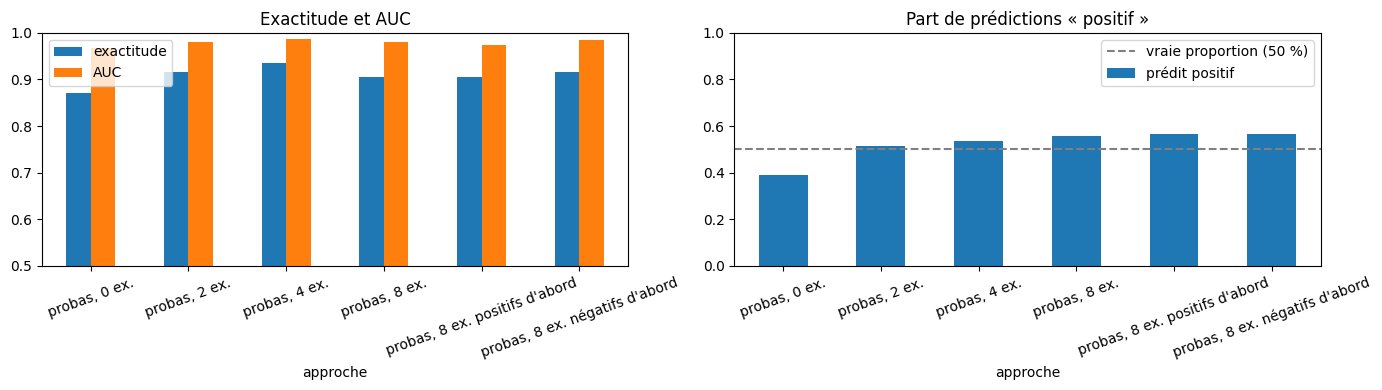

In [43]:
if "probas, 0 ex." not in results_df.index:  # la ligne du zero-shot manque : on la rajoute
    report("probas, 0 ex.", proba_pred, proba_time, proba_scores)
    results_df = pd.DataFrame(results).set_index("approche")

proba_rows = results_df[results_df.index.str.startswith("probas")]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
proba_rows[["exactitude", "AUC"]].plot.bar(ax=axes[0], rot=20, ylim=(0.5, 1), title="Exactitude et AUC")
proba_rows["prédit positif"].plot.bar(ax=axes[1], rot=20, ylim=(0, 1), title="Part de prédictions « positif »")
axes[1].axhline(0.5, color="gray", linestyle="--", label="vraie proportion (50 %)")
axes[1].legend()
plt.tight_layout()
plt.show()

### q5

probas, 0 ex. | effectifs par tranche : [2, 1, 4, 193] | ECE = 0.122
probas, 4 ex. | effectifs par tranche : [2, 1, 2, 195] | ECE = 0.061


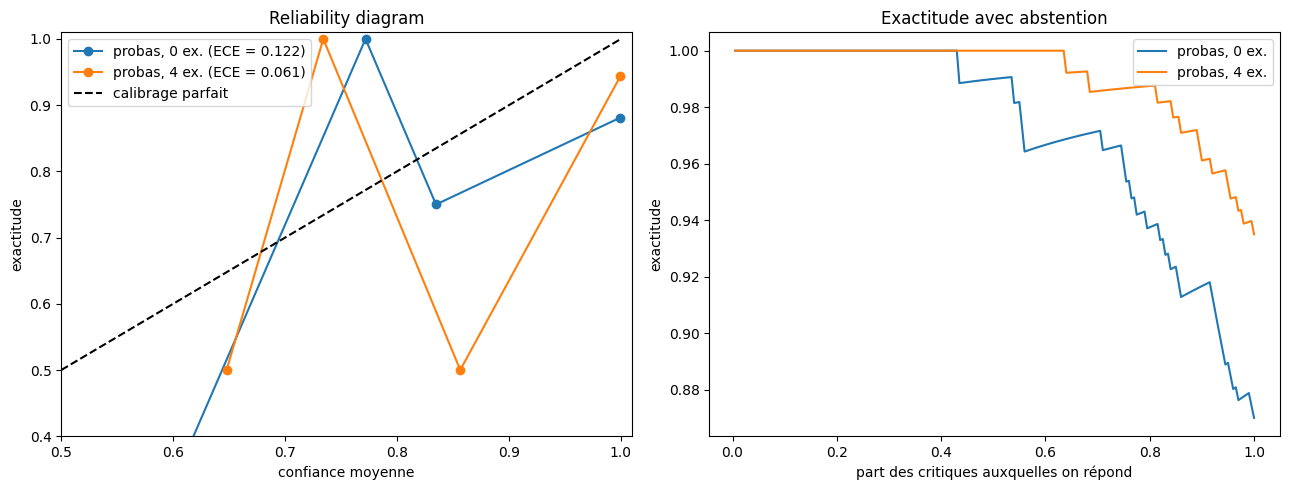

In [44]:
def reliability(scores, n_bins=5):
    """Par tranche de confiance : confiance moyenne, exactitude, effectif. Renvoie aussi l'ECE."""
    confidence = np.maximum(scores, 1 - scores)        # probabilité donnée au label prédit (entre 0,5 et 1)
    correct = (scores > 0.5).astype(int) == y_true
    bins = np.minimum(((confidence - 0.5) / 0.5 * n_bins).astype(int), n_bins - 1)  # tranches 0,5-0,6 ... 0,9-1

    conf, acc, count = [], [], []
    for b in range(n_bins):
        mask = bins == b
        if mask.any():
            conf.append(confidence[mask].mean())
            acc.append(correct[mask].mean())
            count.append(mask.sum())
    conf, acc, count = np.array(conf), np.array(acc), np.array(count)
    ece = np.sum(count * np.abs(acc - conf)) / len(scores)
    return conf, acc, count, ece


compared = ["probas, 0 ex.", "probas, 4 ex."]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name in compared:
    conf, acc, count, ece = reliability(all_scores[name])
    axes[0].plot(conf, acc, "o-", label=f"{name} (ECE = {ece:.3f})")
    print(f"{name} | effectifs par tranche : {count.tolist()} | ECE = {ece:.3f}")
axes[0].plot([0.5, 1], [0.5, 1], "k--", label="calibrage parfait")
axes[0].set(xlabel="confiance moyenne", ylabel="exactitude", title="Reliability diagram", xlim=(0.5, 1.01), ylim=(0.4, 1.01))
axes[0].legend()

# Abstention : on ne répond qu'aux critiques les plus sûres
for name in compared:
    scores = all_scores[name]
    confidence = np.maximum(scores, 1 - scores)
    correct = (scores > 0.5).astype(int) == y_true
    order = np.argsort(-confidence)  # des plus sûres aux moins sûres
    n_answered = np.arange(1, len(scores) + 1)
    axes[1].plot(n_answered / len(scores), np.cumsum(correct[order]) / n_answered, label=name)
axes[1].set(xlabel="part des critiques auxquelles on répond", ylabel="exactitude", title="Exactitude avec abstention")
axes[1].legend()

plt.tight_layout()
plt.show()

Filter:   0%|          | 0/20000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/20000 [00:00<?, ? examples/s]

probas, 0 ex. : seuil optimisé = 0.000 | exactitude test avec 0,5 = 0.870, avec le seuil optimisé = 0.895


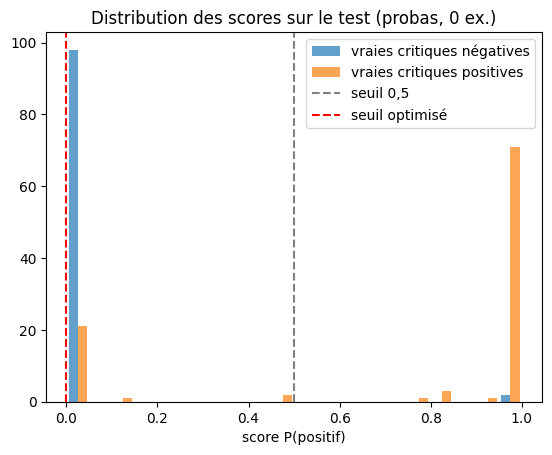

probas, 4 ex. : seuil optimisé = 0.827 | exactitude test avec 0,5 = 0.935, avec le seuil optimisé = 0.935


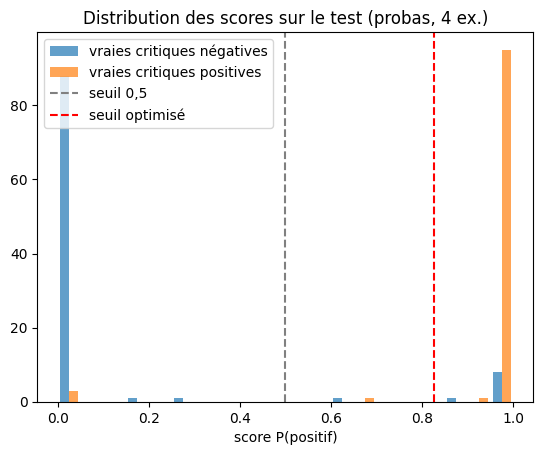

In [45]:
# Le seuil est choisi sur le split VALIDATION, jamais sur le test (sinon on triche).
# Les 4 premières critiques de chaque classe servent déjà d'exemples few-shot : on prend les suivantes.
calib_parts = [validation.filter(lambda ex, l=label: ex["label"] == l).select(range(4, 54)) for label in (0, 1)]
calib_ds = concatenate_datasets(calib_parts)
calib_reviews = [truncate(review) for review in calib_ds["review"]]
calib_true = np.array(calib_ds["label"])

for name, shots in {"probas, 0 ex.": [], "probas, 4 ex.": make_shots(4)}.items():
    # 1) Scores sur la validation, puis seuil qui maximise l'exactitude
    calib_scores = np.array([label_score(review, shots)[0] for review in calib_reviews])
    candidates = np.unique(calib_scores)
    calib_acc = [((calib_scores > t).astype(int) == calib_true).mean() for t in candidates]
    best_threshold = candidates[int(np.argmax(calib_acc))]

    # 2) Application de ce seuil au test
    test_scores = all_scores[name]
    acc_05 = ((test_scores > 0.5).astype(int) == y_true).mean()
    acc_best = ((test_scores > best_threshold).astype(int) == y_true).mean()
    print(f"{name} : seuil optimisé = {best_threshold:.3f} | exactitude test avec 0,5 = {acc_05:.3f}, "
          f"avec le seuil optimisé = {acc_best:.3f}")

    # 3) Histogramme des scores sur le test, par vrai label
    plt.hist([test_scores[y_true == 0], test_scores[y_true == 1]], bins=20, alpha=0.7,
             label=["vraies critiques négatives", "vraies critiques positives"])
    plt.axvline(0.5, color="gray", linestyle="--", label="seuil 0,5")
    plt.axvline(best_threshold, color="red", linestyle="--", label="seuil optimisé")
    plt.xlabel("score P(positif)")
    plt.title(f"Distribution des scores sur le test ({name})")
    plt.legend()
    plt.show()

In [46]:
name = "probas, 4 ex."  # ta meilleure configuration
scores = all_scores[name]
pred = (scores > 0.5).astype(int)
errors = np.where(pred != y_true)[0]
errors = errors[np.argsort(-np.abs(scores[errors] - 0.5))]  # les erreurs les plus « sûres » d'abord

print(f"{len(errors)} erreurs sur {len(y_true)} ({name})\n")
for i in errors:
    print(f"vrai : {LABELS[y_true[i]]:8} | prédit : {LABELS[pred[i]]:8} | score P(positif) = {scores[i]:.2f}")
    print(f"  {reviews[i][:500]}\n")


13 erreurs sur 200 (probas, 4 ex.)

vrai : positif  | prédit : négatif  | score P(positif) = 0.00
  comment une critique peut être pertinente quand sa photo de profil est le choc des titans et que son commentaire est truffé de fautes. scarface772

vrai : positif  | prédit : négatif  | score P(positif) = 0.00
  4 étoiles pour DOUCHET (ex-ce-llent!) 4 étoiles pour ROUCH (ex-ce-llent!) 4 étoiles pour POLLET (ex-ce-llent!) 2 étoiles pour CHABROL (une idée fort intéressante, mais exploitée en dilettante...) 2 étoiles pour ROHMER (idem) 1 étoile pour GODARD (une grosse déception, un air de déjà vu, et quelque chose de très peu convaincant) Un bonus pour la présence de Barbet ! = 3 étoiles, le compte y est !

vrai : négatif  | prédit : positif  | score P(positif) = 1.00
  La chanson cèlèbre de "Blanche Neige et les sept Nains" prête son titre au film de Martin Valente! Le prince laissant place au père...où plutôt à deux pères jouès par François Berlèand et Gèrard Jugnot! Rien de rèvolutionnai

 ## Réponses aux questions

 #### Q : Le modèle a t il un biais vers l'un des labels ?
 R : Sans exemple, le modèle ne prédit positif que dans 39% des cas, alors que l'échantillon contient bien 50% de positifs et 50% de négatifs. Le modèle à donc un biais pour les négatifs.


 #### Q : Le seuil de 0.5 est il le bon ?

 R : Le seuil de 0.5 n'apporte une grande utilité car on constate que les scores sont soit proche de 0 soit proche de 1. En zero shot le meilleur seuil trouvé est proche de 0. Donc le seuil de 0.5 n'est pas le bon.


 #### Q : Quels avantages a l'approche par les probabilités (coût, réponses invalides, possibilité de s'abstenir quand le modèle hésite)?

 R :  
 - cout :  même exactitude (0.87)   
 - réponses invalides  : Aucune réponse invalide possible (tout comme l'approche générative)
 - possibilité de s'abstenir quand le modèle hésite : l'approche donne un score de confiance, ce que l'approche générative ne fait pas. On peut donc laisser de côté les critiques sur lesquelles le modèle hésite, par exemple pour les confier à un humain. Avec 4 exemples, en s'abstenant sur les 20 % de critiques les plus incertaines, l'exactitude passe d'environ 0,935 à environ 0,985. Limite : le modèle est trop sûr de lui (la plupart de ses erreurs ont un score de 0,00 ou 1,00), donc certaines erreurs ne sont pas repérées par ce mécanisme.


 #### Q :  Quelles critiques sont mal classées, et pourquoi (ironie, critiques nuancées...) ?


 R : Des critiques nuancées, De l'ironie, des critiques coupées au mauvais moment, des review sans avis.
 Le modèle capte le sens des mots (pas l'ironie car il ne sais pas si c'est de l'ironie car il n'est pas adapté à détecter cela). Il ne peut pas savoir si une review est complète ou non donc si la parti négative est coupé, il ne peut pas la deviner.